# Tarea 25 · Regresión lineal del cargo acumulado

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/julianschmidt1/tpi-analisis-de-datos/blob/main/notebooks/trabajo/25_regresion_lineal.ipynb)

**TPI · Introducción al Análisis de Datos · UTN FRA · División 343**  
**Integrantes:** Matías, Julián y Emmanuel.

Estimamos `TotalCharges` a partir de `tenure` con una regresión lineal simple. La entrada es `data/processed/telco_clean.csv`. El resultado es el modelo ajustado y su evaluación con R² y MAE sobre datos de prueba.

## Cómo ejecutarlo

- **Local:** instalar `requirements.txt`, abrir el notebook dentro del repositorio y ejecutar todas las celdas.
- **Colab:** abrir el botón. El CSV se lee desde GitHub.


## 1. Carga de datos

Usamos el dataset limpio de la tarea 9. Revisamos que ambas variables sean numéricas, finitas y completas antes de ajustar el modelo.

In [ ]:
from pathlib import Path

import numpy as np
import pandas as pd
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, r2_score
from sklearn.model_selection import train_test_split

try:
    import google.colab
except ImportError:
    EN_COLAB = False
else:
    EN_COLAB = True

ruta_datos = Path("data/processed/telco_clean.csv")
if EN_COLAB:
    fuente = (
        "https://raw.githubusercontent.com/julianschmidt1/tpi-analisis-de-datos/main/"
        + ruta_datos.as_posix()
    )
else:
    actual = Path.cwd().resolve()
    fuente = next(
        (base / ruta_datos for base in (actual, *actual.parents)
         if (base / ruta_datos).is_file()),
        None,
    )
    if fuente is None:
        raise FileNotFoundError("Falta telco_clean.csv. Ejecutá primero la tarea 9.")

datos = pd.read_csv(fuente, usecols=["tenure", "TotalCharges"])
assert all(pd.api.types.is_numeric_dtype(datos[columna]) for columna in datos)
assert np.isfinite(datos.to_numpy()).all(), "Revisá faltantes o valores infinitos."
print(f"Fuente: {fuente}")
print(f"Clientes: {len(datos):,}")

Fuente: F:\codear\analisis-datos\tpi-analisis-de-datos\data\processed\telco_clean.csv
Clientes: 7,043


## 2. Partición y ajuste

El predictor es la antigüedad en meses y el objetivo es el cargo acumulado. Reservamos un 20 % de los clientes para evaluar el modelo y entrenamos con el otro 80 %, usando `random_state=42` para reproducir la división. Esta tarea tiene su propia partición, como indica el plan.

El modelo ajusta una recta con la forma cargo estimado = intercepto + coeficiente × antigüedad. Aprende los dos parámetros únicamente con entrenamiento.

In [ ]:
X = datos[["tenure"]]
y = datos["TotalCharges"]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

modelo = LinearRegression()
modelo.fit(X_train, y_train)
coeficiente = modelo.coef_[0]
intercepto = modelo.intercept_

print(f"Entrenamiento: {len(X_train):,} clientes")
print(f"Prueba: {len(X_test):,} clientes")
print(f"Cargo estimado = {intercepto:.2f} + {coeficiente:.2f} × antigüedad")

Entrenamiento: 5,634 clientes
Prueba: 1,409 clientes
Cargo estimado = -196.86 + 76.73 × antigüedad


## 3. Evaluación sobre prueba

R² compara los errores cuadrados del modelo con la variación del objetivo en prueba. Un valor de 1 corresponde a un ajuste perfecto y puede ser negativo si los errores son grandes. MAE es el promedio de las diferencias absolutas entre los cargos observados y los estimados, expresado en las mismas unidades monetarias que el cargo acumulado.

In [ ]:
predicciones = modelo.predict(X_test)
r2 = r2_score(y_test, predicciones)
mae = mean_absolute_error(y_test, predicciones)

metricas = pd.DataFrame({
    "Métrica": ["R² en prueba", "MAE en prueba"],
    "Valor": [r2, mae],
})
print(metricas.to_string(index=False, float_format=lambda valor: f"{valor:.4f}"))

      Métrica    Valor
 R² en prueba   0.6701
MAE en prueba 892.3789


## 4. Interpretación

Interpretamos los resultados impresos por las celdas anteriores. El coeficiente describe una asociación promedio entre la antigüedad y el total facturado en esta muestra. Los clientes tienen distintos planes y cargos mensuales, por lo que la antigüedad por sí sola deja parte de la variación sin explicar.

In [ ]:
print(
    f"Por cada mes adicional de antigüedad, la recta estima "
    f"{coeficiente:.2f} unidades monetarias más de cargo acumulado."
)
print(
    f"En los clientes de prueba, R² = {r2:.3f}. "
    f"El error absoluto promedio es de {mae:.2f} unidades monetarias."
)
print(
    f"El intercepto es {intercepto:.2f}: es el valor de la recta a cero meses. "
    "Un intercepto negativo carece de interpretación como cargo real "
    "y muestra una limitación del ajuste lineal cerca del origen."
)

Por cada mes adicional de antigüedad, la recta estima 76.73 unidades monetarias más de cargo acumulado.
En los clientes de prueba, R² = 0.670. El error absoluto promedio es de 892.38 unidades monetarias.
El intercepto es -196.86: es el valor de la recta a cero meses. Un intercepto negativo carece de interpretación como cargo real y muestra una limitación del ajuste lineal cerca del origen.


### Estilo común de gráficos

Celda definida en la tarea 16 (paleta, tamaños y la función `guardar_figura`). Se usa para el diagnóstico gráfico de las secciones siguientes.

In [ ]:
from pathlib import Path

import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.ticker import PercentFormatter

try:
    import google.colab
except ImportError:
    EN_COLAB = False
else:
    EN_COLAB = True

if EN_COLAB:
    RAIZ = Path.cwd()
else:
    actual = Path.cwd().resolve()
    RAIZ = next(
        (ruta for ruta in (actual, *actual.parents) if (ruta / 'README.md').is_file()),
        None,
    )
    if RAIZ is None:
        raise FileNotFoundError('Abrí Jupyter dentro del repositorio del TPI.')

TAMANO_FIGURA = (9, 5)
DPI_EXPORTACION = 300
PALETA_CATEGORICA = ['#0072B2', '#D55E00', '#009E73', '#CC79A7', '#E69F00', '#56B4E9']
COLORES_CHURN = {'No': '#0072B2', 'Yes': '#D55E00'}
MAPA_CORRELACION = 'vlag'
CARPETA_FIGURAS = RAIZ / 'reports' / 'figures'

def aplicar_estilo():
    """Aplica el estilo común del TPI a las figuras que se creen después."""
    sns.set_theme(
        style='whitegrid',
        context='notebook',
        font='DejaVu Sans',
        palette=PALETA_CATEGORICA,
        rc={
            'figure.figsize': TAMANO_FIGURA,
            'figure.dpi': 110,
            'figure.facecolor': 'white',
            'axes.facecolor': 'white',
            'axes.titlesize': 14,
            'axes.titleweight': 'bold',
            'axes.labelsize': 12,
            'xtick.labelsize': 11,
            'ytick.labelsize': 11,
            'legend.fontsize': 11,
            'axes.spines.top': False,
            'axes.spines.right': False,
            'grid.alpha': 0.25,
            'savefig.dpi': DPI_EXPORTACION,
            'savefig.facecolor': 'white',
        },
    )

def guardar_figura(fig, nombre):
    """Guarda fig en reports/figures/<nombre>.png a 300 dpi y devuelve Path.

    Usar un nombre sin ruta ni extensión, como '17_histograma_tenure'.
    Un nombre existente se sobrescribe para permitir regenerar el gráfico.
    Guardar antes de plt.show() y cerrar luego con plt.close(fig).
    """
    if not nombre or Path(nombre).name != nombre or Path(nombre).suffix:
        raise ValueError('Usá un nombre sin ruta ni extensión.')
    CARPETA_FIGURAS.mkdir(parents=True, exist_ok=True)
    ruta = CARPETA_FIGURAS / f'{nombre}.png'
    fig.savefig(ruta, dpi=DPI_EXPORTACION, bbox_inches='tight', facecolor='white')
    return ruta

aplicar_estilo()
print('Estilo común aplicado. Exportación PNG a 300 dpi en reports/figures/.')

Estilo común aplicado. Exportación PNG a 300 dpi en reports/figures/.


### 5. Justificación del algoritmo y de las decisiones

**Por qué una regresión lineal simple.** Es un modelo básico y, además, adecuado para este caso: la antigüedad y el cargo acumulado tienen una relación fuerte y casi lineal (Pearson de 0,826 en la tarea 11), y el coeficiente se lee directamente como unidades monetarias por mes.

**Por qué no se estandariza la antigüedad.** En una regresión lineal con un solo predictor, estandarizar no cambia las predicciones, el R² ni el MAE: solo cambia la escala del coeficiente. Como lo que interesa es interpretar la pendiente en dinero por mes, se usa la antigüedad en su unidad original.

**Prevención de fuga de datos (*data leakage*).** La partición 80/20 se hace antes de ajustar nada, el modelo se ajusta (`fit`) solo con los clientes de entrenamiento y los de prueba se usan únicamente para predecir y evaluar. Se fija `random_state=42` para repetir la división.

**Por qué el predictor es solo `tenure`.** Las columnas `ingreso_estimado` (= `MonthlyCharges × tenure`) y `diferencia_facturacion` se calculan a partir del propio cargo acumulado y de la antigüedad: usarlas para predecir `TotalCharges` sería casi circular y filtraría información del objetivo.

Para saber si el modelo aporta algo, lo comparamos con una **referencia**: un "modelo" que siempre predice el promedio de entrenamiento. También comparamos las métricas de entrenamiento y de prueba: si fueran muy distintas, el modelo habría memorizado los datos en vez de generalizar (sobreajuste). Agregamos el **RMSE**, una métrica parecida al MAE que penaliza más los errores grandes.

In [ ]:
from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_squared_error

referencia = DummyRegressor(strategy="mean").fit(X_train, y_train)


def evaluar(nombre, estimador, X_eval, y_eval):
    estimado = estimador.predict(X_eval)
    return {
        "Modelo y conjunto": nombre,
        "R²": r2_score(y_eval, estimado),
        "MAE": mean_absolute_error(y_eval, estimado),
        "RMSE": mean_squared_error(y_eval, estimado) ** 0.5,
    }


comparacion = pd.DataFrame([
    evaluar("Referencia (promedio) · prueba", referencia, X_test, y_test),
    evaluar("Regresión lineal · entrenamiento", modelo, X_train, y_train),
    evaluar("Regresión lineal · prueba", modelo, X_test, y_test),
]).set_index("Modelo y conjunto")
print(f"Promedio de cargo acumulado en entrenamiento (la referencia): {y_train.mean():,.2f}")
comparacion.round(4)

Promedio de cargo acumulado en entrenamiento (la referencia): 2,287.09


,R²,MAE,RMSE
Modelo y conjunto,,,
Referencia (promedio) · prueba,-0.0003,1919.5130,2281.1757
Regresión lineal · entrenamiento,0.6857,875.0435,1268.7251
Regresión lineal · prueba,0.6701,892.3789,1310.1219


**Lectura.** La recta reduce el error absoluto promedio de 1.919,51 (referencia) a 892,38, menos de la mitad. El R² de la referencia es prácticamente cero (−0,0003), como corresponde a un modelo que no usa ninguna información, frente a 0,670 del modelo. Las métricas de entrenamiento (R² 0,686; MAE 875,04) y de prueba (R² 0,670; MAE 892,38) son muy parecidas, así que **no hay señales de sobreajuste**: el modelo generaliza a clientes que no vio. El RMSE (1.310,12) es mayor que el MAE porque penaliza más los errores grandes.

### 6. Diagnóstico gráfico: recta ajustada y residuos

Un **residuo** es la diferencia entre el cargo real y el estimado (`real − estimado`): mide cuánto se equivocó el modelo con cada cliente. Si la recta fuera un buen modelo en todo el rango, los residuos se repartirían alrededor de cero con un ancho parejo. Graficamos la recta sobre los datos de prueba y los residuos en función de la antigüedad.

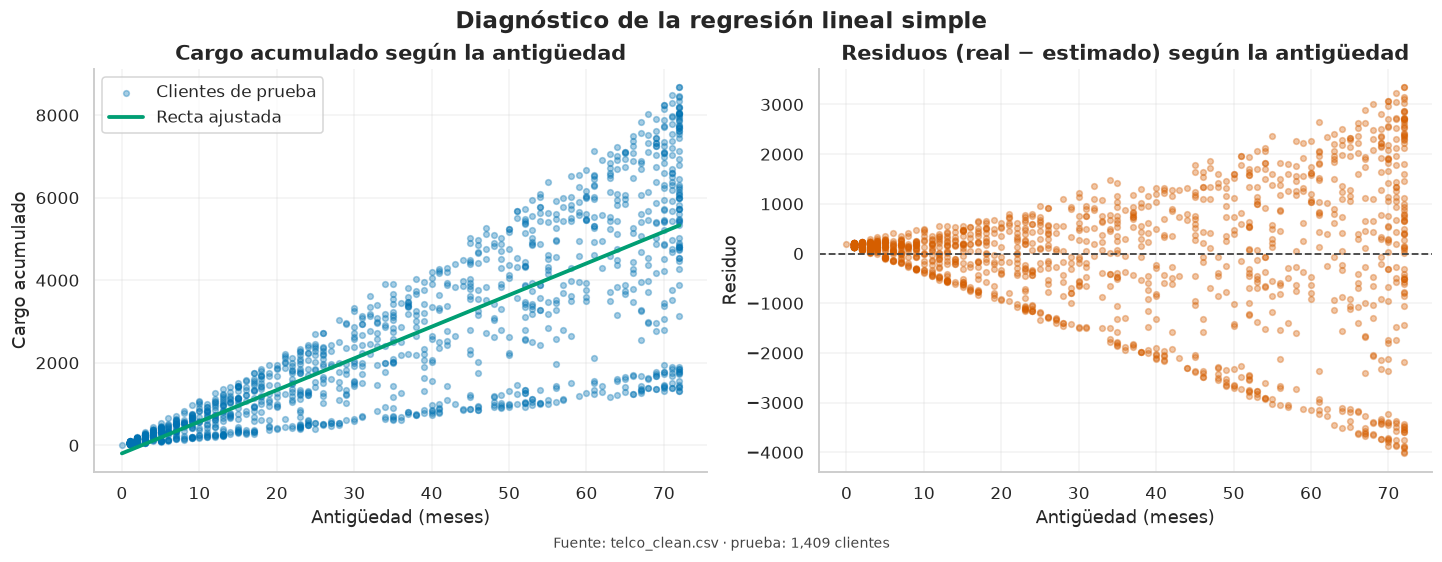

Figura exportada: reports/figures/25_diagnostico_regresion.png


In [ ]:
aplicar_estilo()
residuos = y_test - predicciones

fig, (ax_recta, ax_residuos) = plt.subplots(1, 2, figsize=(13, 5), layout="constrained")

ax_recta.scatter(X_test["tenure"], y_test, s=14, alpha=0.35, color=PALETA_CATEGORICA[0],
                 label="Clientes de prueba")
meses = np.linspace(0, 72, 100)
ax_recta.plot(meses, modelo.predict(pd.DataFrame({"tenure": meses})), color=PALETA_CATEGORICA[2],
              linewidth=2.5, label="Recta ajustada")
ax_recta.set_title("Cargo acumulado según la antigüedad")
ax_recta.set_xlabel("Antigüedad (meses)")
ax_recta.set_ylabel("Cargo acumulado")
ax_recta.legend()

ax_residuos.scatter(X_test["tenure"], residuos, s=14, alpha=0.35, color=PALETA_CATEGORICA[1])
ax_residuos.axhline(0, color="#444444", linestyle="--", linewidth=1.2)
ax_residuos.set_title("Residuos (real − estimado) según la antigüedad")
ax_residuos.set_xlabel("Antigüedad (meses)")
ax_residuos.set_ylabel("Residuo")

fig.suptitle("Diagnóstico de la regresión lineal simple", fontsize=15, fontweight="bold")
fig.supxlabel(f"Fuente: telco_clean.csv · prueba: {len(X_test):,} clientes", fontsize=9, color="#444444")

ruta_figura = guardar_figura(fig, "25_diagnostico_regresion")
plt.show()
plt.close(fig)
print(f"Figura exportada: {ruta_figura.relative_to(RAIZ).as_posix()}")

**Lectura.** A la izquierda, los clientes siguen la recta, pero la nube **se abre como un abanico**: con más meses de antigüedad, la dispersión es mayor, porque hay clientes con planes baratos y caros que acumulan importes muy distintos. A la derecha se ve lo mismo: los residuos no tienen un ancho parejo, sino que **se ensanchan con la antigüedad**. Esta propiedad se llama heterocedasticidad y significa que el error absoluto del modelo no es el mismo para todos los clientes: el MAE promedio resume bien el conjunto, pero oculta que se equivoca más en valor absoluto con los clientes antiguos.

### 7. Dónde acierta y dónde falla el modelo

Dividimos a los clientes de prueba en cuatro tramos de antigüedad y calculamos el error en cada uno. El **error relativo** es el MAE dividido por el cargo real medio del tramo: sirve para comparar tramos con importes muy distintos. El **sesgo** es el residuo medio: si es positivo, el modelo subestima (el cargo real es mayor que el estimado).

In [ ]:
tramos = pd.cut(X_test["tenure"], bins=[-1, 12, 24, 48, 72],
                labels=["0 a 12 meses", "13 a 24 meses", "25 a 48 meses", "49 a 72 meses"])
detalle = pd.DataFrame({"tramo": tramos, "real": y_test, "estimado": predicciones,
                        "residuo": residuos, "error_abs": residuos.abs()})
por_tramo = detalle.groupby("tramo", observed=True).agg(
    clientes=("real", "size"),
    cargo_real_medio=("real", "mean"),
    MAE=("error_abs", "mean"),
    sesgo=("residuo", "mean"),
)
por_tramo["error_relativo"] = por_tramo["MAE"] / por_tramo["cargo_real_medio"]

negativas = detalle[detalle["estimado"] < 0]
print(f"Residuo medio: {residuos.mean():.2f} (desvío {residuos.std():.2f})")
print(f"Correlación entre el error absoluto y la antigüedad: "
      f"{np.corrcoef(residuos.abs(), X_test['tenure'])[0, 1]:.3f}")
print(f"Estimaciones negativas: {len(negativas)} de {len(detalle)} "
      f"({len(negativas) / len(detalle):.1%}); antigüedad máxima entre ellas: "
      f"{int(X_test.loc[negativas.index, 'tenure'].max())} meses")
print(f"El cargo estimado es cero o negativo con menos de {-intercepto / coeficiente:.2f} meses.")
por_tramo.round(2)

Residuo medio: -36.01 (desvío 1310.09)
Correlación entre el error absoluto y la antigüedad: 0.703
Estimaciones negativas: 202 de 1409 (14.3%); antigüedad máxima entre ellas: 2 meses
El cargo estimado es cero o negativo con menos de 2.57 meses.


,clientes,cargo_real_medio,MAE,sesgo,error_relativo
tramo,,,,,
0 a 12 meses,446,253.24,177.35,114.11,0.70
13 a 24 meses,209,1122.21,452.29,-81.14,0.40
25 a 48 meses,287,2372.37,945.62,-195.68,0.40
49 a 72 meses,467,4587.49,1739.49,-61.06,0.38


In [ ]:
mensual = pd.read_csv(fuente, usecols=["tenure", "MonthlyCharges"])
mensual["tramo"] = pd.cut(mensual["tenure"], bins=[-1, 12, 24, 48, 72],
                          labels=["0 a 12 meses", "13 a 24 meses", "25 a 48 meses", "49 a 72 meses"])
print(f"Cargo mensual medio de todos los clientes: {mensual['MonthlyCharges'].mean():.2f}")
print(f"Pendiente de la recta (cargo acumulado por mes): {coeficiente:.2f}")
print()
mensual.groupby("tramo", observed=True)["MonthlyCharges"].agg(clientes="size", cargo_mensual_medio="mean").round(2)

Cargo mensual medio de todos los clientes: 64.76
Pendiente de la recta (cargo acumulado por mes): 76.73



,clientes,cargo_mensual_medio
tramo,,
0 a 12 meses,2186,56.10
13 a 24 meses,1024,61.36
25 a 48 meses,1594,65.93
49 a 72 meses,2239,73.95


**Lectura por tramo.**

- **Clientes nuevos (0 a 12 meses):** el error en valor absoluto es el menor (177,35), pero el relativo es el mayor: **70 %** del cargo real medio (253,24). Aquí la recta es menos útil. Además subestima (sesgo de +114,11).
- **Desde los 13 meses:** el error relativo se estabiliza en torno al **38 % al 40 %** (0,40; 0,40 y 0,38), mientras que el absoluto crece de 452 a 1.739. Es decir: el modelo se equivoca en proporciones parecidas, pero en importes cada vez mayores. Entre los 25 y los 48 meses, la recta sobrestima en promedio (sesgo de −195,68).
- **Estimaciones negativas:** las 202 estimaciones negativas (**14,3 %** de la prueba) corresponden a clientes con 0 a 2 meses de antigüedad. Es una consecuencia del intercepto negativo (−196,86): la recta da cero o menos por debajo de 2,57 meses, algo que no tiene sentido para un cargo acumulado. En un uso práctico, convendría acotar la estimación en cero.

**Cómo leer la pendiente.** La recta estima 76,73 unidades más por cada mes, un valor **mayor que el cargo mensual medio** (64,76). La razón es que los clientes más antiguos tienden a pagar más por mes (de 56,10 entre los de 0 a 12 meses a 73,95 entre los de 49 a 72). Entonces la pendiente mezcla dos efectos: acumular más meses y pertenecer a planes más caros. Por eso describe una asociación y **no** debe leerse como "cada mes adicional hace que el cliente pague 76,73 más".

Un R² de 0,670 no significa que el 67 % de las estimaciones sean correctas ni que la antigüedad *cause* el cargo acumulado: indica que la recta reduce a cerca de un tercio la variación que quedaría sin explicar si se predijera siempre el promedio.

### 8. Conclusión de la regresión

La regresión lineal simple de `TotalCharges` sobre `tenure` es un modelo **adecuado como primera aproximación**: explica cerca de dos tercios de la variación del cargo acumulado en clientes no vistos (R² de 0,670), reduce el error a menos de la mitad de la referencia (MAE de 892,38 frente a 1.919,51) y no muestra sobreajuste.

**Limitaciones:** usa un solo predictor; el error absoluto crece con la antigüedad (heterocedasticidad); falla más en términos relativos con los clientes nuevos, donde incluso genera estimaciones negativas; y su pendiente mezcla el efecto de acumular meses con el de pagar planes más caros. **Mejoras posibles:** incorporar el cargo mensual como segunda variable, modelar con una escala logarítmica o acotar las estimaciones en cero.